In [5]:
# -*- coding: utf-8 -*-
"""LSTM module for model of algorithms

- Author: whikwon
- Contact: whikwon@gmail.com
"""

from typing import Callable

import torch
import torch.nn as nn
import torch.nn.functional as F

from algorithms.common.helper_functions import identity


class LSTM(nn.Module):
    """Baseline of Multilayer perceptron.

    Attributes:
        input_size (int): size of input
        output_size (int): size of output layer
        hidden_sizes (list): sizes of hidden layers
        hidden_activation (function): activation function of hidden layers
        output_activation (function): activation function of output layer
        hidden_layers (list): list containing linear layers
        use_output_layer (bool): whether or not to use the last layer

    """

    def __init__(
        self,
        input_size: int,
        output_size: int,
        hidden_sizes: list,
        hidden_activation: Callable = F.relu,
        output_activation: Callable = identity,
        use_output_layer: bool = True,
        init_w: float = 3e-3,
    ):
        """Initialization.

        Args:
            input_size (int): size of input
            output_size (int): size of output layer
            hidden_sizes (list): number of hidden layers
            hidden_activation (function): activation function of hidden layers
            output_activation (function): activation function of output layer
            use_output_layer (bool): whether or not to use the last layer
            init_w (float): weight initialization bound for the last layer

        """
        super(LSTM, self).__init__()

        self.hidden_sizes = hidden_sizes
        self.input_size = input_size
        self.output_size = output_size
        self.hidden_activation = hidden_activation
        self.output_activation = output_activation
        self.use_output_layer = use_output_layer

        self.hidden_layers: list = []
        in_size = self.input_size
        for i, next_size in enumerate(hidden_sizes):
            lstm = nn.LSTM(in_size, next_size)
            in_size = next_size
            self.add_module("hidden_lstm{}".format(i), lstm)
            self.hidden_layers.append(lstm)

        # set output layers
        if self.use_output_layer:
            self.output_layer = nn.Linear(in_size, output_size)
            self.output_layer.weight.data.uniform_(-init_w, init_w)
            self.output_layer.bias.data.uniform_(-init_w, init_w)

    def get_last_activation(self, x: torch.Tensor) -> torch.Tensor:
        """Get the activation of the last hidden layer."""
        for hidden_layer in self.hidden_layers:
            x = self.hidden_activation(hidden_layer(x))
        return x

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Forward method implementation."""
        assert self.use_output_layer

        x = self.get_last_activation(x)

        output = self.output_layer(x)
        output = self.output_activation(output)

        return output

In [6]:
lstm = LSTM(3, 128, [128, 128, 128])

In [7]:
lstm

LSTM(
  (hidden_lstm0): LSTM(3, 128)
  (hidden_lstm1): LSTM(128, 128)
  (hidden_lstm2): LSTM(128, 128)
  (output_layer): Linear(in_features=128, out_features=128, bias=True)
)

In [9]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
x = np.linspace(-np.pi, np.pi, 201)
noise_generator = lambda: np.random.normal(0, 0.5, size=x.size)

In [11]:
def generate_wave_data(wave='sine', noise=True, iters=10):
    assert wave in ['sine', 'cos']
    
    if wave == 'sine':
        func = np.sin
    else:
        func = np.cos
    
    wave_data = []
    
    for i in range(iters):
        wave_data.append(func(x) + noise_generator())
        
    return wave_data

In [12]:
def plot_overlapped_waves(wave_data):
    iters = len(wave_data)
    
    for i in range(iters):
        plt.plot(x, wave_data[i])
    
    plt.show()

In [13]:
sine_data = generate_wave_data('sine', True, 10)

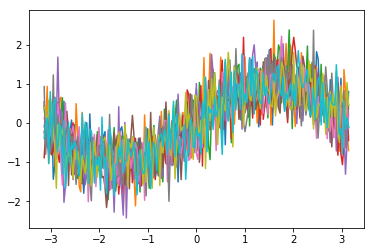

In [14]:
plot_overlapped_waves(sine_data)

In [15]:
cos_data = generate_wave_data('cos', True, 10)

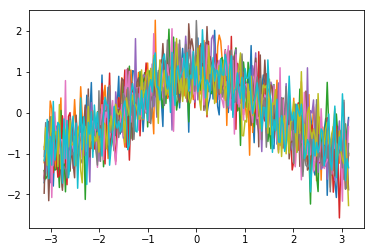

In [16]:
plot_overlapped_waves(cos_data)